# [Lab Session 2](otsu.ipynb)

In [3]:
import numpy as np
import matplotlib.pyplot as plt

**[Task 1.1.]()** Load the image:

In [4]:
imgf= plt.imread('data/NIH3T3/im/dna-0.png')

**[Task 1.2.]()** Quantify the image into 256 bins:

In [5]:
img8=(imgf*255).round().astype(np.uint8)

**[Task 1.3.]()** Compute the image histogram:

In [6]:
x = np.zeros(256)
for i in range(256):
    x[i] =np.sum(img8==i)
plt.figure(figsize=(14,5))
plt.bar(range(256), x,width=1)

<BarContainer object of 256 artists>

Show the computed histogram:

<BarContainer object of 256 artists>

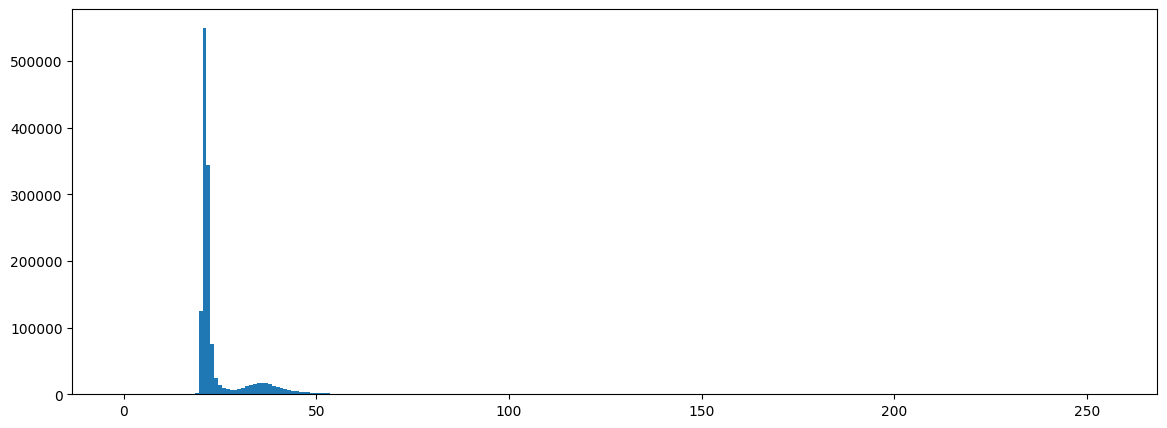

In [8]:
plt.figure(figsize=(14,5))
plt.bar(range(256), x, width=1)

**[Task 1.4.]()** Implement the method of Otsu:

In [ ]:
list_T=[]
for t in range (1,256):
    class1=img8[img8<t] #von den 256 bins die nehmen die unter dem schwellenwert sind
    class2=img8[img8>=t]
    if class1.size==0 or class2.size==0:
        T=np.inf # unendlich groß - man kann kein minimum findne
    else:
        T=class1.size*np.var(class1)+class2.size*np.var(class2)
    
    list_T.append(T)
    threshold=list_T.index(min(list_T))+1
print("optimal threshold:", threshold)


#erklärung für conci: img enthält die tatsächlichen Helligkeitswerte der einzelnen Pixel.
# h enthält dagegen, wie oft jeder Helligkeitswert vorkommt.
# #Das Histogramm speichert also Häufigkeiten und nicht direkt die einzelnen Pixelintensitäten
#Varianz der Pixelintensitäten innerhalb der beiden Klassen minimieren. 
#also nicht häufigekiten deswegen geht das mit dem histogram nicht

optimal threshold: 31


**[Task 1.5.]()** Perform Otsu thresholding:

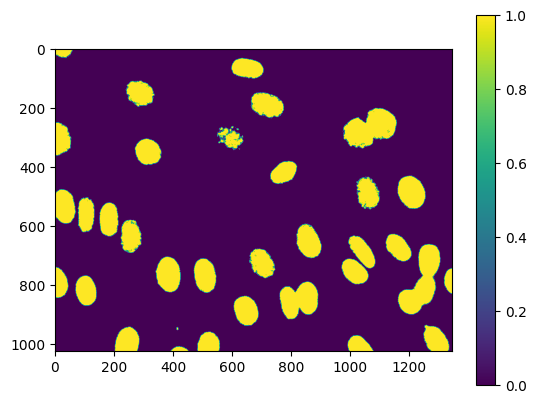

In [11]:
img_out= img8 >= threshold
plt.figure()
plt.imshow(img_out)
plt.colorbar()
plt.show()

**[Task 1.6.]()** Compute the Dice coefficient:

0.30676019584286063


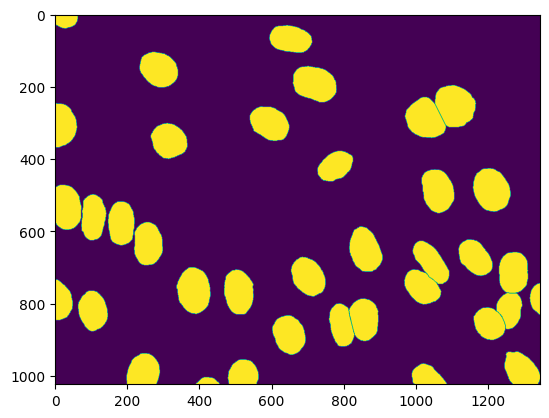

In [13]:
ground= plt.imread('data/NIH3T3/gt/0.png')
plt.imshow(ground)

H = np.asarray(ground, dtype=bool)
G= np.asarray(imgf, dtype=bool)
GH = np.logical_and(G,H).sum()
dice= 2*GH/(G.sum()+H.sum())
print(dice)